In [3]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
months = ['202507', '202508', '202509', '202510', '202511', '202512']
alldata = pd.concat([pd.read_csv(f'CRMLSSold{m}.csv') for m in months], ignore_index=True)

df = alldata[
    (alldata['PropertyType'] == 'Residential')
    & (alldata['PropertySubType'] == 'SingleFamilyResidence')
    & (alldata['ClosePrice'] > 0)
    & (alldata['LivingArea'] > 0)
    & (alldata['BedroomsTotal'] > 0)
    & (alldata['BathroomsTotalInteger'] > 0)
    & (alldata['LotSizeSquareFeet'] > 0)
]
df = df.drop_duplicates(subset='ListingKey')
df = df.dropna(axis=1, how='all')
df.info()

<class 'pandas.DataFrame'>
Index: 65961 entries, 3 to 131918
Data columns (total 70 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   BuyerAgentAOR             65950 non-null  str    
 1   ListAgentAOR              65950 non-null  str    
 2   Flooring                  43132 non-null  str    
 3   ViewYN                    59721 non-null  object 
 4   WaterfrontYN              27 non-null     object 
 5   BasementYN                1581 non-null   object 
 6   PoolPrivateYN             60899 non-null  object 
 7   OriginalListPrice         65830 non-null  float64
 8   ListingKey                65961 non-null  int64  
 9   ListAgentEmail            65728 non-null  str    
 10  CloseDate                 65961 non-null  str    
 11  ClosePrice                65961 non-null  float64
 12  ListAgentFirstName        65490 non-null  str    
 13  ListAgentLastName         65954 non-null  str    
 14  Latitude             

In [3]:
df[['ClosePrice', 'LivingArea', 'LotSizeSquareFeet', 'BedroomsTotal', 'BathroomsTotalInteger']].describe()

,ClosePrice,LivingArea,LotSizeSquareFeet,BedroomsTotal,BathroomsTotalInteger
count,6.596100e+04,65961.000000,6.596100e+04,65961.000000,65961.000000
mean,1.318712e+06,2039.909169,4.582001e+05,3.490184,2.618153
std,8.499397e+06,1048.415143,1.872465e+07,0.960814,1.124951
min,4.850000e+02,105.000000,4.000000e-02,1.000000,1.000000
25%,6.200000e+05,1380.000000,5.663000e+03,3.000000,2.000000
50%,8.790000e+05,1811.000000,7.278000e+03,3.000000,2.000000
75%,1.389990e+06,2427.000000,1.045400e+04,4.000000,3.000000
max,9.895000e+08,56500.000000,1.938943e+09,19.000000,35.000000


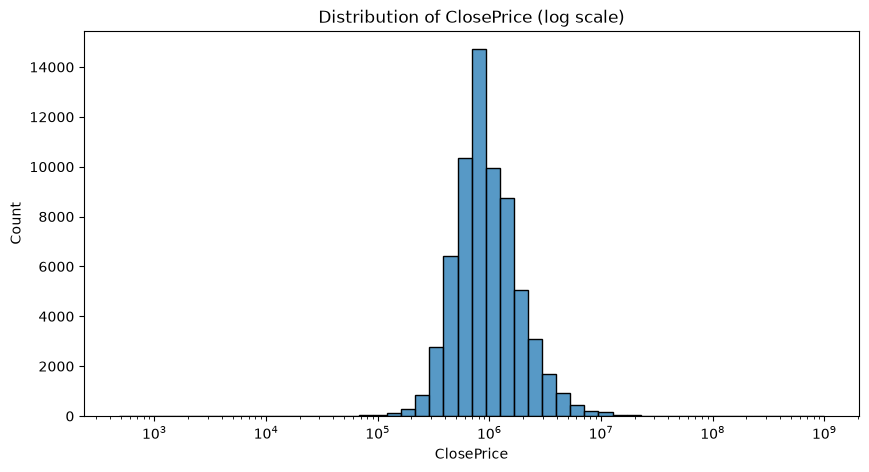

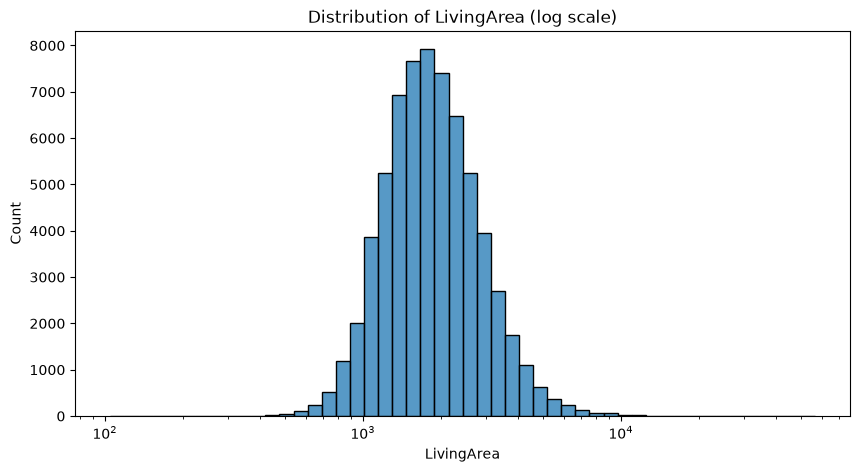

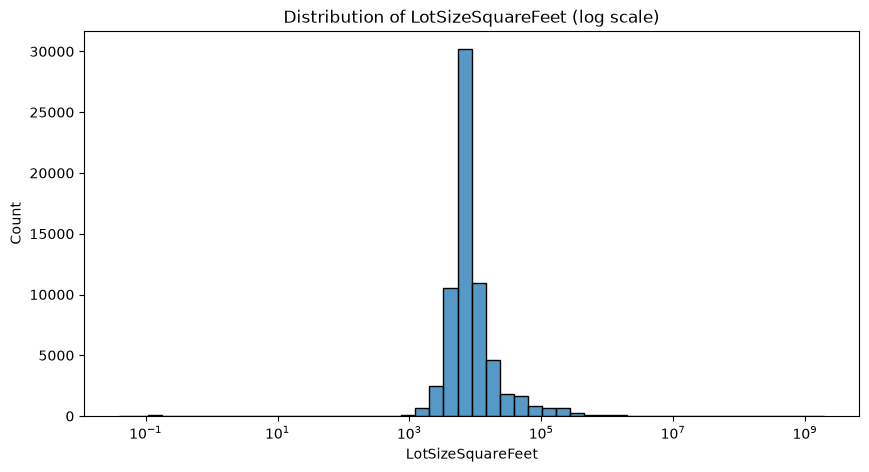

In [4]:
for col in ['ClosePrice', 'LivingArea', 'LotSizeSquareFeet']:
    plt.figure(figsize=(10, 5))
    sns.histplot(df[col], bins=50, log_scale=True)
    plt.title(f'Distribution of {col} (log scale)')
    plt.show()

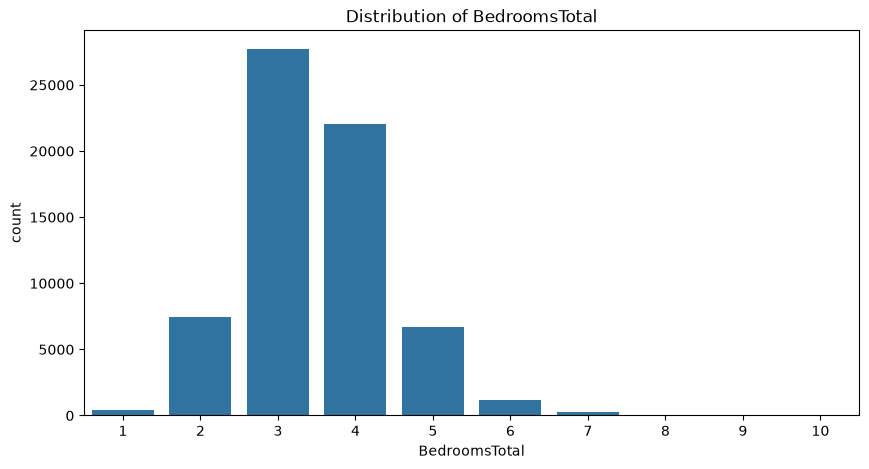

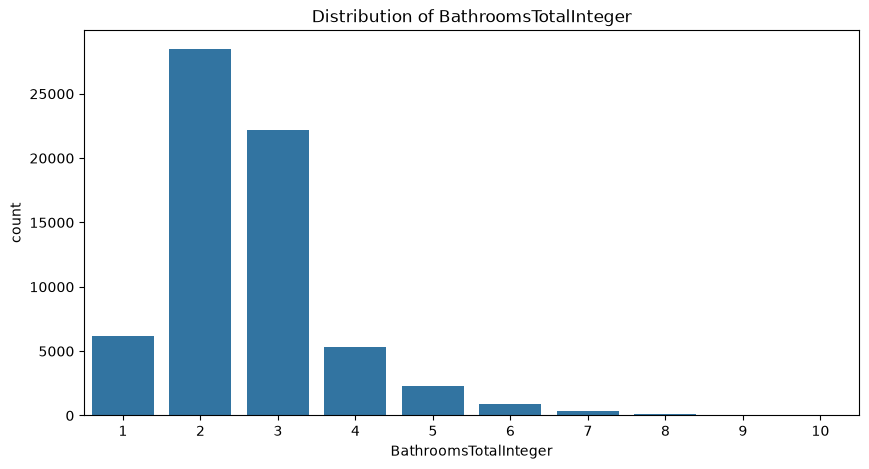

In [5]:
for col in ['BedroomsTotal', 'BathroomsTotalInteger']:
    plt.figure(figsize=(10, 5))
    sns.countplot(x=df[col][df[col] <= 10].astype(int))
    plt.title(f'Distribution of {col}')
    plt.show()